In [4]:
# STEP 0 (run once): install the SDKs
# WHY (tech): Installs each provider's Python SDK, which handles HTTP requests, authentication and response parsing.
# ELI5: Download a translator app for each AI company.
!pip install -q -U google-genai openai anthropic
# If you later get an ImportError: Runtime -> Restart session, then run the cells again (skip this one).

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.2 which is incompatible.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.6.1 which is incompatible.


In [5]:
from google import genai
from google.genai import types
from google.colab import userdata
gemini = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))
MODEL = "gemini-3.8-flash"
test = gemini.models.generate_content(model=MODEL, contents="Say OK")
print("✅ Gemini connected:", test.text)

from openai import OpenAI
from google.colab import userdata
openai_client = OpenAI(api_key=userdata.get("OPENAI_API_KEY"))
MODEL = "gpt-6.1-sol"
test = openai_client.chat.completions.create(model=MODEL, messages=[{"role": "user", "content": "Say OK"}])
print("✅ OpenAI connected:", test.choices[0].message.content)

import anthropic
from google.colab import userdata
claude = anthropic.Anthropic(api_key=userdata.get("ANTHROPIC_API_KEY"))
MODEL = "claude-sonnet-5-5"
test = claude.messages.create(model=MODEL, max_tokens=20, messages=[{"role": "user", "content": "Say OK"}])
print("✅ Claude connected:", test.content[-1].text)

from openai import OpenAI
from google.colab import userdata
groq = OpenAI(api_key=userdata.get("GROQ_API_KEY"), base_url="https://api.groq.com/openai/v1")
MODEL = "openai/gpt-oss-120b"
test = groq.chat.completions.create(model=MODEL, messages=[{"role": "user", "content": "Say OK"}])
print("✅ Groq connected:", test.choices[0].message.content)

✅ Gemini connected: OK
✅ OpenAI connected: OK
✅ Claude connected: OK
✅ Groq connected: OK


## 3. Tool Calling

### What an LLM can't do

Let's ask something that needs **live** data.

In [6]:
response = gemini.models.generate_content(
    model="gemini-3.8-flash",
    contents="How did Nvidia's stock price move in the last 3 hours? Give me some latest news about it.",
)

print(response.text)

I do not have access to real-time financial market data or live news feeds, so I cannot provide the exact movement of Nvidia's (NVDA) stock price over the last three hours or breaking news from today.

To see live, minute-by-minute updates and the latest headlines, you can check:

* **Live Tickers & Charts:** [Google Finance](https://www.google.com/finance/quote/NVDA:NASDAQ), [Yahoo Finance](https://finance.yahoo.com/quote/NVDA), or [TradingView](https://www.tradingview.com/symbols/NASDAQ-NVDA/)
* **Financial News:** [Bloomberg](https://www.bloomberg.com), [CNBC](https://www.cnbc.com), or [Reuters](https://www.reuters.com)


The LLM only knows what it learned during training. It can't search the web, check live data or use your apps. It can only **write text**.

To let it **do** things, we give it **tools**.

A **tool** is a function the LLM can ask to use. The LLM decides **by itself** when it needs one.

3.1 Built-in tool: Google Search
Gemini comes with a Google Search tool. We just switch it on.

In [7]:
search_tool = types.Tool(google_search=types.GoogleSearch())

response = gemini.models.generate_content(
    model="gemini-3.8-flash",
    contents="Give me some latest news about NVIDIA as of Oct, 2026!",
    config=types.GenerateContentConfig(tools=[search_tool]),
)

print(response.text)

search_info = response.candidates[0].grounding_metadata

print("Gemini searched for:", search_info.web_search_queries)

Major developments and news surrounding NVIDIA in **October 2026** include:

---

### 1. GTC Berlin Keynote & European AI Expansion (Oct. 20–22, 2026)
* **Keynote Address:** Jensen Huang headlined **GTC Berlin**, emphasizing the shift toward an "AI manufacturing economy" and industrial AI factories. 
* **Cost of AI Infrastructure:** Huang stated that establishing a 1-gigawatt (GW) AI factory requires approximately **$50 billion** in capital expenditure.
* **European Investments:** NVIDIA highlighted more than **$10 billion** invested across European AI startups, universities, and regional partnerships, announcing new startup funding across France, the UK, Sweden, and Germany.
* **Product Focus:** Demonstrations featured the **Vera Rubin** rack-scale architectures and the **Vera MGX** compute nodes, alongside updates to the DGX Spark developer platforms.

---

### 2. Supply Chain & Advanced Packaging Commitments
* **Amkor Advanced Packaging Deal:** NVIDIA expanded long-term advanced pac

We never told Gemini *when* to search. It saw the question needs fresh information, searched, and answered.

See what it searched for:

In [8]:
search_info = response.candidates[0].grounding_metadata

print("Gemini searched for:", search_info.web_search_queries)

Gemini searched for: ['nvidia latest news 2024', '"Jensen Huang" "October 2026"', '"Nvidia" "October 2026"', 'nvidia news october 2024']


Open AI Google search

In [9]:
response = openai_client.responses.create(
    model="gpt-6.1-sol",
    input="Give me some latest news about NVIDIA as of Oct, 2026!",
    tools=[{"type": "web_search"}],          # give GPT the built-in web search tool
)
print(response.output_text)

# Show what GPT searched for
for item in response.output:
    if item.type == "web_search_call":
        print("OpenAI searched for:", getattr(item.action, "query", None))

Here are **six notable NVIDIA headlines as of October 31, 2026**—excluding developments first reported in November:

### 1. October 29: Report raises national-security questions around Jensen Huang
*The New York Times* reported that U.S. officials suspected a Chinese business executive with close access to Huang of passing intelligence to Beijing. **NVIDIA disputed the implications**, saying the interactions were ordinary customer meetings and that customers received neither sensitive trade secrets nor national-security information. These were reported allegations, not established findings of wrongdoing by Huang. ([gvwire.com](https://gvwire.com/2026/10/29/nvidia-chief-seen-as-target-of-chinese-spy-plot/?jet_blog_ajax=1&nocache=1794165842))

### 2. October 28: DOJ scrutinizes proposed Hugging Face acquisition
Reuters reported that the U.S. Justice Department was asking how NVIDIA’s **$12.93 billion proposed acquisition of Hugging Face** could affect AI competition. Questions included w

ANTTROPIC CLAUD

In [10]:
response = claude.messages.create(
    model="claude-sonnet-5-5",
    max_tokens=2000,
    messages=[{"role": "user", "content": "Give me some latest news about NVIDIA as of Oct, 2026!"}],
    tools=[{"type": "web_search_20260209", "name": "web_search", "max_uses": 3}],  # max 3 searches
)

# Claude's reply has several blocks: search calls, results and text. Print only the text.
print("".join(b.text for b in response.content if b.type == "text"))

# Show what Claude searched for safely
for b in response.content:
    if b.type == "server_tool_use":
        # Safely extract the query string regardless of key structure
        query = b.input.get("query") or b.input.get("params", {}).get("query") or b.input
        print("Claude searched for:", query)

Here's what I found for NVIDIA in October 2026, plus a major development from just after the month ended.

## October 2026 highlights

- **$1B for US science (Oct 8):** NVIDIA announced commitments valued at $1 billion to build out US capacity for super intelligence research and development. The fields include quantum computing, healthcare and energy security. It was announced at a Washington, D.C. science event.
- **OCP Global Summit (Oct 12):** NVIDIA contributed key Vera Rubin rack and compute tray designs to OCP through the open NVIDIA MGX architecture. The aim is to give system builders a common foundation for next-generation AI factory infrastructure.
- **AI-defined fabs (Oct 14):** NVIDIA introduced cuPotential, a new CUDA-X library for building AI agents that simulate how atoms and molecules interact. It also said NanoVDB helped Lam Research achieve 30x faster simulation.
- **GTC Berlin (Oct 20–22):** Huang said a 1-gigawatt AI factory would cost operators about $50 billion to 

Groq

In [11]:
response = groq.chat.completions.create(
    model="openai/gpt-oss-120b",
    messages=[{"role": "user", "content": "Give me some latest news about NVIDIA as of Oct, 2026!"}],
    tools=[{"type": "browser_search"}],      # Groq's built-in browsing tool
    tool_choice="required",                  # force it to search
)
msg = response.choices[0].message
print(msg.content)

# Show what Groq did (it may be empty for some responses)
print("Groq tools used:", getattr(msg, "executed_tools", None))

**NVIDIA – Highlights from October 2026**

| Date (Oct 2026) | Headline | What’s new |
|-----------------|----------|------------|
| **Oct 27** | **NVIDIA & Oracle expand “Vera Rubin” to multi‑gigawatt scale** | NVIDIA and Oracle announced that Oracle Cloud Infrastructure will host NVIDIA Vera Rubin NVL72 systems at multi‑gigawatt capacity, adding general‑availability of Vera Rubin GPUs and the new NVIDIA Vera CPUs for agentic workloads【1†L13-L18】. |
| **Oct 27** | **NVIDIA & Meta deepen Muse partnership** | The two companies will broaden work on Meta’s Muse and Muse‑family models, roll out more Vera Rubin GPUs and Vera CPUs on Meta’s infrastructure, and explore the OpenShell reference architecture for secure agents. NVIDIA is also investing $3 bn in Meta’s equity offering【3†L11-L18】【3†L23-L28】. |
| **Oct 21** | **Launch of the OpenShell Reference Architecture** | NVIDIA unveiled a full‑stack, secure runtime for enterprise AI agents that combines Vera Rubin GPUs, Vera CPUs and BlueFiel

3.2 Your own tool: a stock price tracker
Built-in tools are handy, but most tools an FDE builds are your own code: a client's database, their CRM, an internal API.

Any Python function can be a tool. Let's build one that shows how a US stock moved in the last few hours, using Yahoo Finance (yfinance, no API key needed).

First, let's look at the data: Nvidia's price every 15 minutes, for the last 3 hours.

<Axes: title={'center': 'NVDA · last 3 hours'}, xlabel='Datetime'>

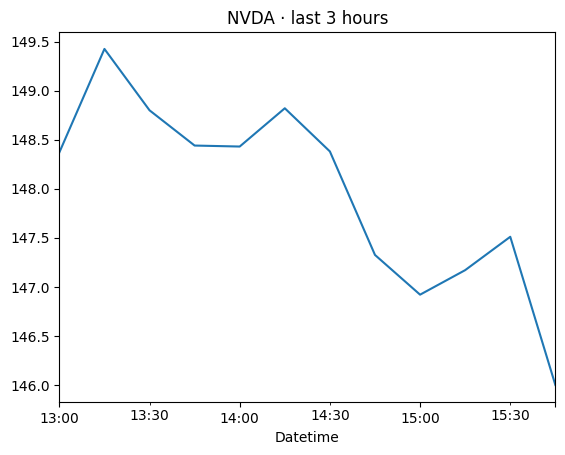

In [12]:
import yfinance as yf

prices = yf.Ticker("NVDA").history(period="5d", interval="15m")["Close"]

prices.tail(12).plot(title="NVDA · last 3 hours")

**Note:** if the US market is closed right now, you see the last 3 hours of the most recent trading day.

Now we wrap this into a function. The **docstring** (text inside `""" """`) tells Gemini what the tool does and when to use it.

In [14]:
def get_stock_prices(ticker: str, hours: int) -> str:  #tool function
    """Get a US stock's price every 15 minutes for the last few hours. Use tickers like NVDA, GOOGL, AAPL, TSLA."""
    print(f"Tool called! {ticker}, last {hours} hours")

    prices = yf.Ticker(ticker).history(period="5d", interval="15m")["Close"]
    return prices.tail(hours * 4).round(2).to_string()

In [15]:
print(get_stock_prices("NVDA", 3))

Tool called! NVDA, last 3 hours
Datetime
2026-11-19 13:00:00-05:00    148.37
2026-11-19 13:15:00-05:00    149.43
2026-11-19 13:30:00-05:00    148.80
2026-11-19 13:45:00-05:00    148.44
2026-11-19 14:00:00-05:00    148.43
2026-11-19 14:15:00-05:00    148.82
2026-11-19 14:30:00-05:00    148.38
2026-11-19 14:45:00-05:00    147.32
2026-11-19 15:00:00-05:00    146.92
2026-11-19 15:15:00-05:00    147.17
2026-11-19 15:30:00-05:00    147.51
2026-11-19 15:45:00-05:00    146.00


In [16]:
response = gemini.models.generate_content(
     model="gemini-3.8-flash",     #Model+ LLM
    contents="How did Nvidia's stock move in the last 3 hours? Give the start price, end price, % change and your analysis",
    config=types.GenerateContentConfig(tools=[get_stock_prices]), # tool called
)

print(response.text)

Tool called! NVDA, last 3 hours
Here is the summary and analysis of Nvidia's (NVDA) stock performance over the last 3 hours:

### Key Metrics
* **Start Price (13:00):** $148.37
* **End Price (15:45):** $146.00
* **Absolute Change:** -$2.37
* **Percentage Change:** **-1.60%**

---

### Price Movement Overview
| Time | Price ($) |
| :--- | :--- |
| **13:00** | 148.37 |
| **13:15** | 149.43 *(Period High)* |
| **13:30** | 148.80 |
| **13:45** | 148.44 |
| **14:00** | 148.43 |
| **14:15** | 148.82 |
| **14:30** | 148.38 |
| **14:45** | 147.32 |
| **15:00** | 146.92 |
| **15:15** | 147.17 |
| **15:30** | 147.51 |
| **15:45** | 146.00 *(Period Low)* |

---

### Analysis
1. **Initial Push to Resistance (13:00 – 13:15):** The stock started with upside momentum, touching a 3-hour peak of **$149.43**, but quickly failed to maintain ground above $149.
2. **Consolidation (13:30 – 14:30):** For about an hour, the price traded sideways within a tight range ($148.38 – $148.82), showing indecision bef

See the **"Tool called!"** line? Here's what happened:

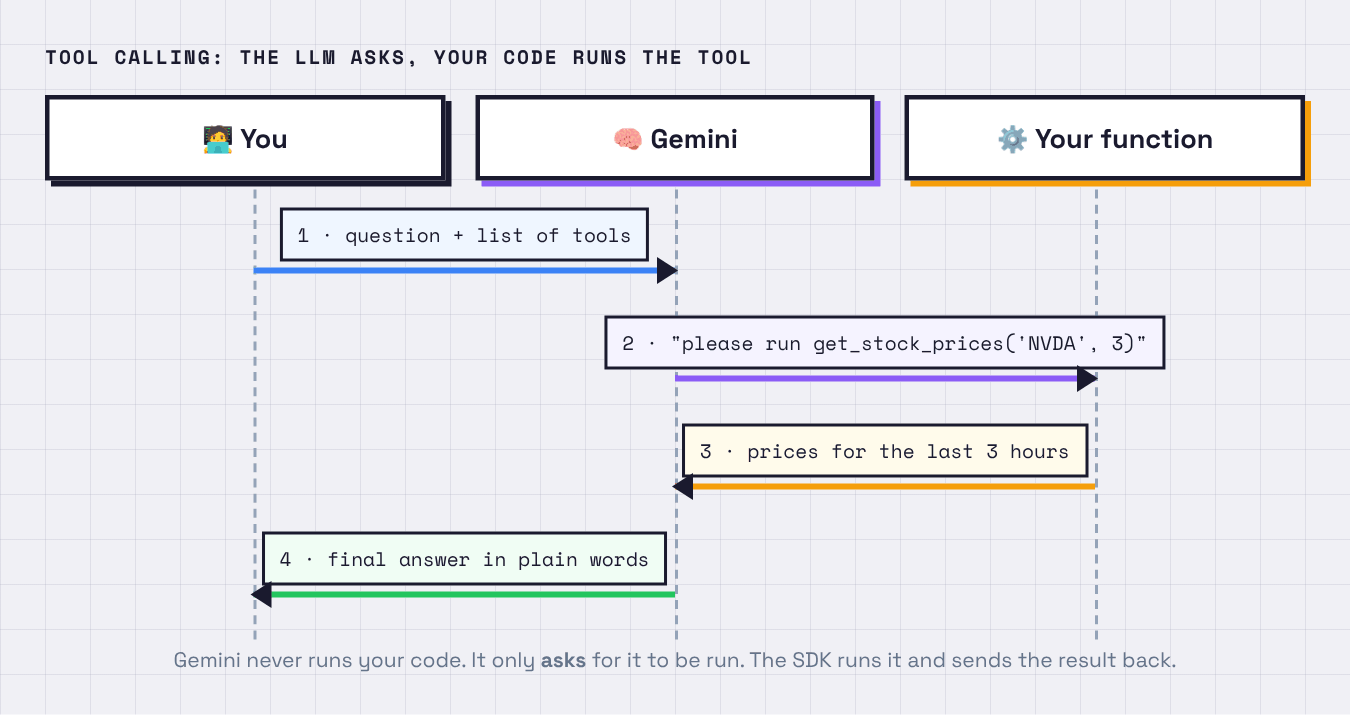

**Gemini never runs your code.** It only *asks* for it to be run. The SDK runs your function and sends the result back.

Now a question where Gemini has to work out the inputs by itself:

In [17]:
response = gemini.models.generate_content(
    model="gemini-3.8-flash",
    contents="Compare Nvidia and Google over the last 5 hours. Which one did better?",
    config=types.GenerateContentConfig(tools=[get_stock_prices]),
)

print(response.text)

Tool called! NVDA, last 5 hours
Tool called! GOOGL, last 5 hours
Over the last 5 hours, both stocks experienced a decline, but **Nvidia (NVDA) performed better** as it lost less percentage value than Google (GOOGL).

---

### **Performance Comparison**

* **Nvidia (NVDA):**
  * **Starting Price (11:00):** $153.26
  * **Latest Price (15:45):** $146.00
  * **Change:** -$7.26 (**-4.74%**)

* **Google (GOOGL):**
  * **Starting Price (11:00):** $288.71
  * **Latest Price (15:45):** $272.50
  * **Change:** -$16.21 (**-5.61%**)

---

### **Conclusion**
**Nvidia did better**, declining by **4.74%** compared to Google's larger decline of **5.61%**.


Apple tesla compare

In [18]:
response = gemini.models.generate_content(
    model="gemini-3.8-flash",
    contents="Compare Apple and Tesla over the last 5 hours. Which one did better?",
    config=types.GenerateContentConfig(tools=[get_stock_prices]),
)

print(response.text)

Tool called! AAPL, last 5 hours
Tool called! TSLA, last 5 hours
Over the last 5 hours (from 11:00 to 15:45), **Apple (AAPL)** performed better than **Tesla (TSLA)**.

---

### **Performance Summary**

| Metric | Apple (AAPL) | Tesla (TSLA) |
| :--- | :--- | :--- |
| **Start Price (11:00)** | $349.42 | $381.22 |
| **Latest Price (15:45)** | $349.11 | $374.43 |
| **Price Change** | -$0.31 | -$6.79 |
| **Percentage Change** | **-0.09%** | **-1.78%** |
| **5-Hour High** | $350.11 (12:15) | $382.33 (11:30) |
| **5-Hour Low** | $347.35 (12:00) | $374.43 (15:45) |

---

### **Conclusion**
While both stocks trended downward over the 5-hour window:
* **Apple** remained virtually flat, dipping by just **-0.09% (-$0.31)**.
* **Tesla** experienced a larger sell-off, dropping by **-1.78% (-$6.79)** and finishing near its low for the period. 

Therefore, **Apple did better**.


## 4. Structured Outputs

Tools let the LLM **do** things. Structured outputs control what comes **out** of it.

Normally, the LLM replies with a paragraph. Easy for people to read, hard for code to use.

response is text can not stored in the db so

In [19]:
prices = get_stock_prices("NVDA", 3)

response = gemini.models.generate_content(
    model="gemini-3.8-flash",
    contents="Summarise how this stock moved: " + prices,
)

print(response.text)
print(type(response.text)) # response is text can not stored in the db so

Tool called! NVDA, last 3 hours
Here is a summary of the stock's price action from 13:00 to 15:45 on November 19:

### **Overview**
The stock experienced an overall **bearish (downward) trend** during the afternoon session, falling **-$2.37 (-1.60%)** from its starting price to finish at the session low.

---

### **Key Metrics**
* **Starting Price (13:00):** 148.37
* **Session High (13:15):** 149.43
* **Session Low / Closing Price (15:45):** 146.00
* **Total Range:** $3.43

---

### **Phase-by-Phase Movement**

1. **Early Spike (13:00 – 13:15):**
   The stock opened at 148.37 and rallied strongly within the first 15 minutes to reach the day's peak of **149.43**.
2. **Consolidation (13:30 – 14:30):**
   After retreating from the high, the price flattened out and moved sideways in a tight range between **148.38 and 148.82** for about an hour.
3. **First Drop & Brief Bounce (14:30 – 15:30):**
   Sellers took control at 14:45, triggering a sharp decline down to **146.92** by 15:00. Buyers

In [20]:
print(type(response.text))

<class 'str'>


Nice to read. But if your code needs the % change to send an alert, it has to dig it out of the text.

With structured outputs, we describe the exact shape we want using a Pydantic class. Gemini fills in those fields and returns JSON (named key/value pairs like {"ticker": "NVDA"}).

In [21]:
from pydantic import BaseModel
from typing import Literal

class StockMove(BaseModel):
    ticker: str
    start_price: float
    end_price: float
    percent_change: float
    trend: Literal["up", "down", "flat"]

In [28]:
from pydantic import BaseModel
from typing import Literal

class StockMove(BaseModel):
    ticker: str
    start_price: float
    end_price: float
    percent_change: float
    trend: Literal["up", "down", "flat"]

response = gemini.models.generate_content(
    model="gemini-3.8-flash",
    # contents=f"Summarise how NVIDIA stock moved: {prices.to_string()}",
    contents = "Summarise how NVIDIA stock moved: " + prices,
    config=types.GenerateContentConfig(
        response_mime_type="application/json",
        response_schema=StockMove,
    ),
)

response.parsed

print(response.parsed.model_dump_json(indent=2))

move = response.parsed

if move.trend == "down":
    print(f"Alert: {move.ticker} fell {move.percent_change}%")
else:
    print(f"{move.ticker} is {move.trend}: {move.percent_change}%")

{
  "ticker": "NVDA",
  "start_price": 148.37,
  "end_price": 146.0,
  "percent_change": -1.6,
  "trend": "down"
}
Alert: NVDA fell -1.6%


In [24]:
print(response.parsed.model_dump_json(indent=2))

{
  "ticker": "NVDA",
  "start_price": 148.37,
  "end_price": 146.0,
  "percent_change": -1.6,
  "trend": "down"
}


Now our code can use each field directly:

In [26]:
move = response.parsed

if move.trend == "down":
    print(f"Alert: {move.ticker} fell {move.percent_change}%")
else:
    print(f"{move.ticker} is {move.trend}: {move.percent_change}%")

Alert: NVDA fell -1.6%


**Note:** structured outputs control the **shape** of the answer, not its accuracy. For exact maths, calculate it in Python from the prices.

Open AI Code


In [36]:
response = openai_client.beta.chat.completions.parse(
    model="gpt-6.1-sol",
    messages=[
        {"role": "user", "content": "Summarise how NVIDIA stock moved: " + prices}
    ],
    response_format=StockMove,
)
move = response.choices[0].message.parsed
print(move.model_dump_json(indent=2))

if move.trend == "down":
    print(f"Alert: {move.ticker} fell {move.percent_change}%")
else:
    print(f"{move.ticker} is {move.trend}: {move.percent_change}%")

{
  "ticker": "NVDA",
  "start_price": 148.37,
  "end_price": 146.0,
  "percent_change": -1.6,
  "trend": "down"
}
Alert: NVDA fell -1.6%


Claud

In [40]:
response = claude.messages.parse(
    model="claude-sonnet-5-5",
    max_tokens=1000,                   # required for Claude
    messages=[{"role": "user", "content": "Summarise how NVIDIA stock moved: " + prices}],
    output_format=StockMove,           # "fill in this form"
)
move = response.parsed_output           # the filled-in StockMove
print(move.model_dump_json(indent=2))

if move.trend == "down":
    print(f"Alert: {move.ticker} fell {move.percent_change}%")
else:
    print(f"{move.ticker} is {move.trend}: {move.percent_change}%")

{
  "ticker": "NVDA",
  "start_price": 148.37,
  "end_price": 146.0,
  "percent_change": -1.6,
  "trend": "down"
}
Alert: NVDA fell -1.6%


Groq

In [43]:
response = groq.chat.completions.create(
    model="openai/gpt-oss-120b",
    messages=[{"role": "user", "content": "Summarise how NVIDIA stock moved: " + prices}],
    response_format={
        "type": "json_schema",
        "json_schema": {"name": "stock_move", "schema": StockMove.model_json_schema()},  # form → schema
    },
)
move = StockMove.model_validate_json(response.choices[0].message.content)  # text → checked form
print(move.model_dump_json(indent=2))

if move.trend == "down":
    print(f"Alert: {move.ticker} fell {move.percent_change}%")
else:
    print(f"{move.ticker} is {move.trend}: {move.percent_change}%")

{
  "ticker": "NVDA",
  "start_price": 148.37,
  "end_price": 146.0,
  "percent_change": -1.596,
  "trend": "down"
}
Alert: NVDA fell -1.596%
